# ASTR 457: The Midterm

Posted Thu Oct 8, due Wed Oct 14 by Noon (fork → PR, as always). Graded like a lab.

Three parts. Each is designed to test something every lab so far has come back to - which error bar is the right one, whether the model needs the extra parameter, and whether the check you ran could have failed. You've now got the tools to do all of this, so let's do it on numbers you haven't seen: 250 real Type Ia supernovae, and someone else's analysis of real white dwarfs.

Part 1 is 30 pts (6 each), Part 2 is 45 pts, and Part 3 is 25 pts. You'll need 2b and 2c right to get 2d right.

Remember, the rules are the syllabus rules - open book, you can use AI tools (document them in 3b), you can work together and discuss problems and solutions, but you have to write up your own solution and run it on **your own data** in `data/<your netid>/` (nobody else's numbers will match yours).

Put your notebook in `submissions/<your netid>/midterm.ipynb`. The path below (`DATA`) reaches your files from there. Make sure it runs top to bottom from a fresh kernel ("Restart & Run All") - that is how it will be graded, and how it will be run if you defend it.

Throughout, make sure every number you quote has a unit, an error bar and a sensible number of digits (two significant figures on the error bar, and round the value to match).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'ym31'
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

rng = np.random.default_rng(457)

## Part 1: Error bars (30 pts, 6 each)

Five short scenarios. Each one is a number someone handed you - say whether it's right, compute the right one, and say in a sentence or two why. Show the code. Each of these should be about 20 minutes of work.

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

(1) WLS: k = 0.2432 +/- 0.0097 mag/airmass (quoted errors only), m0 = 25.066 +/- 0.016 mag
(2) polyfit cov=True:       k = 0.2432 +/- 0.0221
    polyfit cov='unscaled': k = 0.2432 +/- 0.0097  (same as my WLS)
(3) chi2 = 67.2 for 13 dof, chi2/dof = 5.17 (expect 1 +/- 0.39)
    polyfit error / WLS error = 2.273;  sqrt(chi2/dof) = 2.273
    P(chi2 >= this | quoted errors right) = 2.6e-09
    P(chi2 <= this | quoted errors right) = 0.9999999974
(4) normalized residuals: std = 2.27, MAD-sigma = 2.05, |r|>2 for 4 of 15 points, worst = -5.2
    without the worst point: k = 0.2550, chi2/dof = 3.10, rescaled sigma_k = 0.0176
    jackknife sigma_k = 0.0220


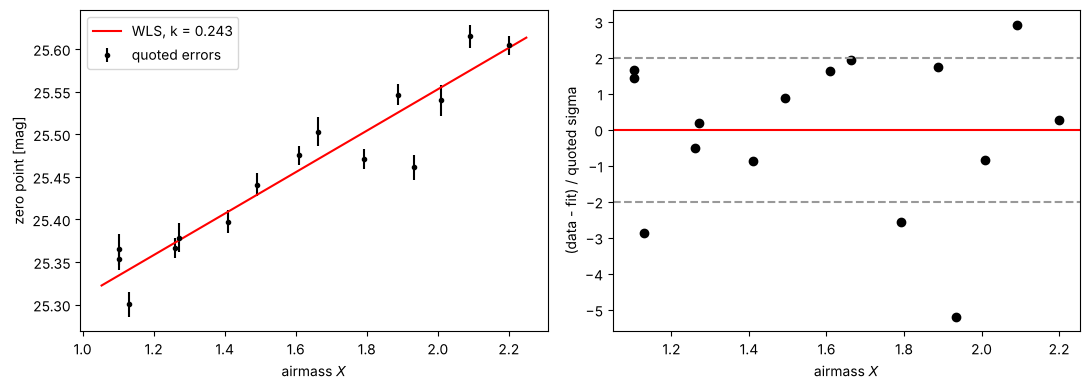

In [2]:
# 1a: your work here
d = load('p1a_extinction')
X, zp, sq = d['airmass'].to_numpy(), d['zeropoint_mag'].to_numpy(), d['sigma_quoted_mag'].to_numpy()
n = len(X)

def wls(A, y, sy):
    Si = np.diag(1 / sy**2)
    cov = np.linalg.inv(A.T @ Si @ A)
    return cov @ A.T @ Si @ y, cov

# (1) weighted least squares with the quoted errors, by hand
A = np.vstack([X, np.ones(n)]).T
(k, m0), cov_q = wls(A, zp, sq)
sk_q = np.sqrt(cov_q[0, 0])
print(f"(1) WLS: k = {k:.4f} +/- {sk_q:.4f} mag/airmass (quoted errors only), m0 = {m0:.3f} +/- {np.sqrt(cov_q[1,1]):.3f} mag")

# (2) polyfit with cov=True
p_pf, cov_pf = np.polyfit(X, zp, 1, w=1/sq, cov=True)
p_un, cov_un = np.polyfit(X, zp, 1, w=1/sq, cov='unscaled')
sk_pf = np.sqrt(cov_pf[0, 0])
print(f"(2) polyfit cov=True:       k = {p_pf[0]:.4f} +/- {sk_pf:.4f}")
print(f"    polyfit cov='unscaled': k = {p_un[0]:.4f} +/- {np.sqrt(cov_un[0,0]):.4f}  (same as my WLS)")

# (3) chi^2
r = (zp - A @ np.array([k, m0])) / sq
chi2 = np.sum(r**2); dof = n - 2
print(f"(3) chi2 = {chi2:.1f} for {dof} dof, chi2/dof = {chi2/dof:.2f} (expect 1 +/- {np.sqrt(2/dof):.2f})")
print(f"    polyfit error / WLS error = {sk_pf/sk_q:.3f};  sqrt(chi2/dof) = {np.sqrt(chi2/dof):.3f}")
print(f"    P(chi2 >= this | quoted errors right) = {stats.chi2.sf(chi2, dof):.1e}")
print(f"    P(chi2 <= this | quoted errors right) = {stats.chi2.cdf(chi2, dof):.10f}")

# (4) is it a few outliers or all the errors? look at the normalized residuals
mad_sig = 1.4826 * np.median(np.abs(r - np.median(r)))
print(f"(4) normalized residuals: std = {np.std(r, ddof=2):.2f}, MAD-sigma = {mad_sig:.2f}, "
      f"|r|>2 for {np.sum(np.abs(r) > 2)} of {n} points, worst = {r[np.argmax(np.abs(r))]:+.1f}")
# drop the single worst point and refit, to see if it is driving chi2
keep = np.abs(r) < np.abs(r).max()
(k_d, _), cov_d = wls(A[keep], zp[keep], sq[keep])
r_d = (zp[keep] - A[keep] @ wls(A[keep], zp[keep], sq[keep])[0]) / sq[keep]
chi2_d = np.sum(r_d**2)
print(f"    without the worst point: k = {k_d:.4f}, chi2/dof = {chi2_d/(n-3):.2f}, "
      f"rescaled sigma_k = {np.sqrt(cov_d[0,0]*chi2_d/(n-3)):.4f}")
# jackknife as an independent check of the error on k that doesn't use the quoted errors' size
k_jk = np.array([wls(np.delete(A, i, 0), np.delete(zp, i), np.delete(sq, i))[0][0] for i in range(n)])
sk_jk = np.sqrt((n - 1) / n * np.sum((k_jk - k_jk.mean())**2))
print(f"    jackknife sigma_k = {sk_jk:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
xx = np.linspace(X.min() - 0.05, X.max() + 0.05, 100)
ax[0].errorbar(X, zp, sq, fmt='k.', label='quoted errors')
ax[0].plot(xx, k*xx + m0, 'r-', label=f'WLS, k = {k:.3f}')
ax[0].set_xlabel('airmass $X$'); ax[0].set_ylabel('zero point [mag]'); ax[0].legend()
ax[1].plot(X, r, 'ko'); ax[1].axhline(0, color='r')
for s_ in (-2, 2): ax[1].axhline(s_, color='0.6', ls='--')
ax[1].set_xlabel('airmass $X$'); ax[1].set_ylabel('(data - fit) / quoted sigma')
plt.tight_layout(); plt.show()

**ANSWER:**

1. Weighted least squares with the quoted errors gives $k = 0.2432 \pm 0.0097$ mag/airmass (and $m_0 = 25.066 \pm 0.016$ mag). That error is $\sqrt{[(A^T\Sigma^{-1}A)^{-1}]_{00}}$, so it only knows about the quoted $\sigma_i$.

2. `np.polyfit(..., w=1/sigma, cov=True)` gives the same $k$ but $\pm 0.0221$ mag/airmass, 2.27 times bigger. With `cov=True` numpy does not trust the weights as real errors: it multiplies the covariance by $\chi^2/(N - \mathrm{deg} - 1) = \chi^2/13$, i.e. it rescales the errors until $\chi^2_{\rm red} = 1$. The ratio of the two error bars is exactly $\sqrt{\chi^2/\nu} = 2.273$. `cov='unscaled'` gives back my 0.0097.

3. $\chi^2 = 67.2$ for $\nu = 15 - 2 = 13$ dof, so $\chi^2/\nu = 5.2$, when a good fit should give $1 \pm 0.39$. If the quoted errors were right, the chance of a $\chi^2$ at least this large is $P = 2.6\times10^{-9}$ (`stats.chi2.sf`); the chance of one this small or smaller is essentially 1, so it is not suspiciously small, it is far too large.

4. I'd quote $k = 0.243 \pm 0.022$ mag/airmass. Rescaling to $\chi^2_{\rm red}=1$ is circular if you use it to claim the model fits, but here I'm not testing the model: extinction linear in airmass is the physics, and the question is only how big the real errors are. Before rescaling I checked the residuals to see whether one or two outliers are behind the big $\chi^2$ (the Cepheid lesson): they aren't. The normalized residuals have std 2.27 and a robust MAD-$\sigma$ of 2.05, so the whole distribution is about twice too wide, not just a tail. The worst point is at $-5.2\sigma$; dropping it changes $k$ to 0.255 and still leaves $\chi^2/\nu = 3.1$ (rescaled $\sigma_k = 0.018$), so it doesn't explain it. A jackknife, which doesn't use the size of the quoted errors at all, gives $\sigma_k = 0.022$, the same as the rescaled number. So the pipeline's error bars are underestimated by about a factor of 2 (probably a missing systematic term, e.g. flat-fielding or transparency changes through the night), and the quoted-error-only 0.0097 is over-confident by that factor.


### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [3]:
# 1b: your work here
d = load('p1b_centroid')
s_psf, N, s_quoted = d['psf_sigma_arcsec'][0], d['n_photons'][0], d['quoted_sigma_x0_arcsec'][0]
# Gaussian PSF: Fisher information per photon is 1/s_psf^2, so I = N/s_psf^2 and the bound is s_psf/sqrt(N)
crb = s_psf / np.sqrt(N)
print(f"PSF sigma = {s_psf:.3f} arcsec, N = {N} photons")
print(f"Cramer-Rao bound: sigma_x0 >= {crb:.4f} arcsec")
print(f"quoted: {s_quoted:.4f} arcsec = {s_quoted/crb:.2f} x the bound")

# check the bound by simulation: the sample mean is unbiased and efficient for a Gaussian PSF
xhat = rng.normal(0, s_psf, size=(20000, N)).mean(axis=1)
print(f"scatter of the sample mean over 20000 fake stars: {xhat.std():.4f} arcsec")
# what simple mistakes give the quoted number?
print(f"if each photon is counted twice (N -> 2N): {s_psf/np.sqrt(2*N):.4f} arcsec")
print(f"photons needed to really reach the quoted error: {(s_psf/s_quoted)**2:.0f}")

PSF sigma = 1.316 arcsec, N = 396 photons
Cramer-Rao bound: sigma_x0 >= 0.0661 arcsec
quoted: 0.0450 arcsec = 0.68 x the bound


scatter of the sample mean over 20000 fake stars: 0.0665 arcsec
if each photon is counted twice (N -> 2N): 0.0467 arcsec
photons needed to really reach the quoted error: 854


**ANSWER:**

1. For photons drawn from a Gaussian PSF of width $\sigma_{\rm PSF}$, each photon carries Fisher information $1/\sigma_{\rm PSF}^2$ about the position, so $I = N/\sigma_{\rm PSF}^2$ and the Cramér-Rao bound is $\sigma_{x_0} \ge \sigma_{\rm PSF}/\sqrt{N} = 1.316/\sqrt{396} = 0.066$ arcsec. The plain sample mean already reaches it (my 20000 fake stars give 0.0665 arcsec), so no weighting scheme can do better for an unbiased estimator.

2. No. The quoted 0.045 arcsec is 0.68 times the bound; to really get there you'd need about 850 photons, not 396. So the number can't be the error of an unbiased position estimate. Either the estimator is biased (e.g. a weighting that pulls toward the starting guess or the window centre has a smaller scatter, but then its real error, the bias plus the scatter, is bigger and the quoted number leaves the bias out), or it is just a mistake. Two concrete mistakes that would give something this small:
   - **counting each photon twice** (e.g. summing over photons and over pixels, or treating weights as extra counts): $N \to 2N$ gives $1.316/\sqrt{792} = 0.047$ arcsec, almost exactly their number;
   - **computing the error with the true position plugged in** (testing the weighting scheme on simulations where the weights were centred on the known answer), which uses information the real measurement doesn't have.
   (Mixing up FWHM and $\sigma$ would go the other way, FWHM is $2.35\sigma$, so it would make the error bigger, not smaller.)


### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

best depth = 2.402 ppt, d2(-2lnL)/d depth^2 = 32.07 ppt^-2
classmate: sigma = 0.177 ppt;  correct: sigma = sqrt(2/curv) = 0.250 ppt;  ratio = 1.414
Delta(-2lnL)=1 interval: [2.150, 2.649] ppt  ->  2.402 -0.253 +0.247 ppt
predicted coverage of the classmate's intervals: P(|z| < 1/sqrt2) = 0.520
simulated (5000 datasets): classmate 0.519, correct sigma 0.686  (binomial scatter +/- 0.007)


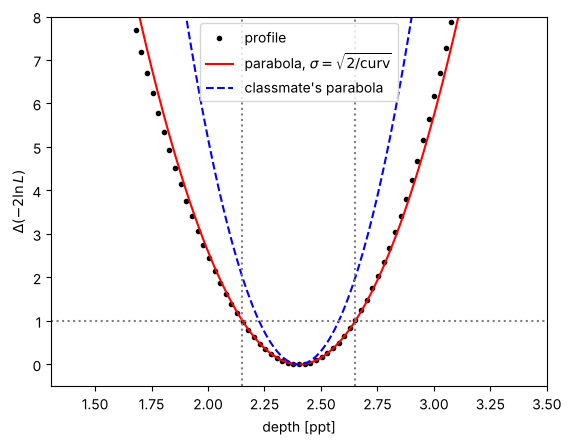

In [4]:
# 1c: your work here
d = load('p1c_profile')
dep, m2l = d['depth_ppt'].to_numpy(), d['minus2lnL'].to_numpy()
i0 = np.argmin(m2l)
# fit a parabola to the points near the minimum to get the best depth and the curvature
sel = slice(max(i0 - 5, 0), i0 + 6)
a2, a1, a0 = np.polyfit(dep[sel], m2l[sel], 2)
best = -a1 / (2*a2); curv = 2*a2              # d^2(-2lnL)/d depth^2
sig_classmate = 1 / np.sqrt(curv)
sig_right = np.sqrt(2 / curv)                   # factor 2: -2lnL is chi^2, not -lnL
print(f"best depth = {best:.3f} ppt, d2(-2lnL)/d depth^2 = {curv:.2f} ppt^-2")
print(f"classmate: sigma = {sig_classmate:.3f} ppt;  correct: sigma = sqrt(2/curv) = {sig_right:.3f} ppt;  ratio = {sig_right/sig_classmate:.3f}")

# (2) read the Delta(-2lnL) = 1 interval straight off the profile (linear interpolation)
from scipy.optimize import brentq
m2l_min = a0 - a1**2 / (4*a2)
f = lambda t: np.interp(t, dep, m2l) - m2l_min - 1
lo, hi = brentq(f, dep[0], best), brentq(f, best, dep[-1])
print(f"Delta(-2lnL)=1 interval: [{lo:.3f}, {hi:.3f}] ppt  ->  {best:.3f} -{best-lo:.3f} +{hi-best:.3f} ppt")

# (3) coverage of the classmate's +/- sigma
pred = 2*stats.norm.cdf(1/np.sqrt(2)) - 1
truth = 2.40                                     # a truth I choose
fake = rng.normal(truth, sig_right, 5000)        # fake best-fit depths
cov_cl = np.mean(np.abs(fake - truth) < sig_classmate)
cov_ok = np.mean(np.abs(fake - truth) < sig_right)
print(f"predicted coverage of the classmate's intervals: P(|z| < 1/sqrt2) = {pred:.3f}")
print(f"simulated (5000 datasets): classmate {cov_cl:.3f}, correct sigma {cov_ok:.3f}  "
      f"(binomial scatter +/- {np.sqrt(0.68*0.32/5000):.3f})")

xx = np.linspace(dep.min(), dep.max(), 300)
plt.plot(dep, m2l - m2l_min, 'k.', label='profile')
plt.plot(xx, (xx - best)**2 / sig_right**2, 'r-', label=r'parabola, $\sigma=\sqrt{2/{\rm curv}}$')
plt.plot(xx, (xx - best)**2 / sig_classmate**2, 'b--', label="classmate's parabola")
plt.axhline(1, color='0.5', ls=':'); plt.axvline(lo, color='0.5', ls=':'); plt.axvline(hi, color='0.5', ls=':')
plt.ylim(-0.5, 8); plt.xlabel('depth [ppt]'); plt.ylabel(r'$\Delta(-2\ln L)$'); plt.legend(); plt.show()

**ANSWER:**

1. A parabola fit to the profile near its minimum gives the best depth 2.402 ppt and curvature $d^2(-2\ln L)/d\,\mathrm{depth}^2 = 32.1$ ppt$^{-2}$. Since $-2\ln L \approx \mathrm{const} + (\delta - \hat\delta)^2/\sigma^2$, its second derivative is $2/\sigma^2$, so the right error is $\sigma = \sqrt{2/32.1} = 0.25$ ppt. The classmate's $1/\sqrt{32.1} = 0.18$ ppt is too small by a factor $\sqrt 2 = 1.41$: they used the formula for the curvature of $-\ln L$ on $-2\ln L$ (the factor of 2 we keep in `cov = 2*inv(H)`). Best depth: $2.40 \pm 0.25$ ppt.

2. Reading off $\Delta(-2\ln L) = 1$ directly gives $[2.150, 2.649]$ ppt, i.e. $2.40^{+0.25}_{-0.25}$ ppt ($-0.253$, $+0.247$). It is symmetric to within 0.006 ppt and matches the curvature answer, so the profile is very close to a parabola near the minimum and the curvature error is fine at $1\sigma$. Further out it does get lopsided: at $\Delta(-2\ln L) = 9$ (3$\sigma$) the interval is $-0.79$/$+0.72$ ppt, wider on the shallow side, so for a 3$\sigma$ limit I'd read it off the profile rather than use the parabola; the classmate's problem is only the factor of 2. (One more caveat: this profile was computed with the other parameters fixed at their best values, so strictly it's a conditional slice; if the depth is correlated with e.g. the duration or baseline, the marginal error would be a bit bigger still, cf. 1e.)

3. $\pm\sigma/\sqrt2$ is $\pm 0.707$ of the true $\sigma$, so the coverage should be $P(|z| < 1/\sqrt2) = 52\%$, not 68%. Simulating 5000 best-fit depths around a truth of 2.40 ppt with the correct $\sigma$: the classmate's intervals contain the truth 51.9% of the time, and the correct ones 68.6% (binomial scatter $\pm 0.7\%$). So about half of their intervals would miss the truth.


### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

M2 = 10.3 +3.5 / -2.6 Msun (median, 16th-84th percentiles)
(i)   variance         = 10.6 Msun^2   -> not even in Msun; sqrt would be 3.25 Msun
(ii)  p84 - p16        = 6.12 Msun     -> full 68% width, 2.00 x the half-width 3.06 Msun
(iii) std/sqrt(8000)   = 0.036 Msun    -> Monte Carlo error on the mean, 84 x too small
mean = 10.79, median = 10.32, mode ~ 9.7 Msun;  skewness = 0.96
upper error / lower error = 1.33
   2.5th percentile: samples 5.8,  symmetric Gaussian 4.1 Msun
  97.5th percentile: samples 18.3,  symmetric Gaussian 16.3 Msun


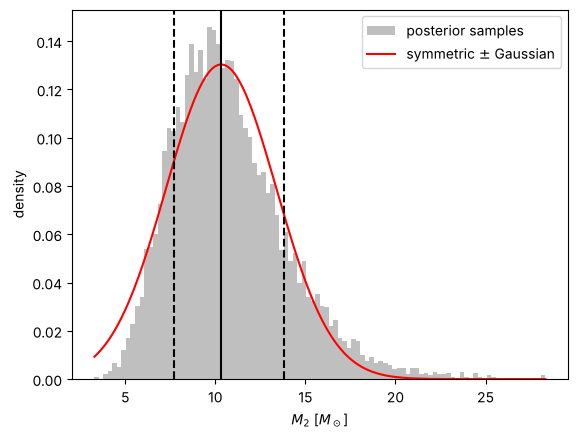

In [5]:
# 1d: your work here
M2 = load('p1d_mass_samples')['M2_Msun'].to_numpy()
lo, med, hi = np.percentile(M2, [16, 50, 84])
print(f"M2 = {med:.1f} +{hi-med:.1f} / -{med-lo:.1f} Msun (median, 16th-84th percentiles)")
sig_half = (hi - lo) / 2                         # half the 68% width, the closest thing to a 1 sigma
v, w, sem = M2.var(ddof=1), hi - lo, M2.std(ddof=1)/np.sqrt(M2.size)
print(f"(i)   variance         = {v:.1f} Msun^2   -> not even in Msun; sqrt would be {np.sqrt(v):.2f} Msun")
print(f"(ii)  p84 - p16        = {w:.2f} Msun     -> full 68% width, {w/sig_half:.2f} x the half-width {sig_half:.2f} Msun")
print(f"(iii) std/sqrt(8000)   = {sem:.3f} Msun    -> Monte Carlo error on the mean, {sig_half/sem:.0f} x too small")
print(f"mean = {M2.mean():.2f}, median = {med:.2f}, mode ~ ", end='')
h, e = np.histogram(M2, 80); print(f"{0.5*(e[h.argmax()]+e[h.argmax()+1]):.1f} Msun;  skewness = {stats.skew(M2):.2f}")
print(f"upper error / lower error = {(hi-med)/(med-lo):.2f}")
# a symmetric Gaussian with the same median and sigma would put this much mass below zero / at low masses:
g = rng.normal(med, sig_half, M2.size)
for q in (2.5, 97.5):
    print(f"  {q:>4}th percentile: samples {np.percentile(M2, q):.1f},  symmetric Gaussian {np.percentile(g, q):.1f} Msun")

plt.hist(M2, 100, density=True, color='0.75', label='posterior samples')
xx = np.linspace(M2.min(), M2.max(), 300)
plt.plot(xx, stats.norm.pdf(xx, med, sig_half), 'r-', label=r'symmetric $\pm$ Gaussian')
for q in (lo, med, hi): plt.axvline(q, color='k', ls='--' if q != med else '-')
plt.xlabel(r'$M_2$ [$M_\odot$]'); plt.ylabel('density'); plt.legend(); plt.show()

**ANSWER:**

1. $M_2 = 10.3^{+3.5}_{-2.6}\ M_\odot$ (median, 16th-84th percentiles).

2. Taking a "$1\sigma$" of about 3 $M_\odot$ (half the 16-84 width is 3.06 $M_\odot$):
   - (i) The variance, 10.6 $M_\odot^2$, isn't an error bar at all, it has units of $M_\odot^2$. Its square root (the std, 3.25 $M_\odot$) would be roughly right, but the variance as quoted is off by a factor of about 3.5 and in the wrong units.
   - (ii) The 84th minus the 16th percentile, 6.1 $M_\odot$, is the full width of the 68% interval, so as a $\pm 1\sigma$ it's 2 times too big.
   - (iii) std$/\sqrt{8000}$ = 0.036 $M_\odot$ is the Monte Carlo error on the posterior mean, i.e. how well the 8000 samples pin down the mean, not how well the data pin down the mass. It's about 84 times too small and would keep shrinking as you ran the chain longer.

3. No. The posterior is skewed to high masses (skewness 0.96; the mean 10.8 is above the median 10.3, which is above the mode near 9.7 $M_\odot$), and the upper error is 1.33 times the lower one. The tails show it best: the 2.5th and 97.5th percentiles of the samples are 5.8 and 18.3 $M_\odot$, while a symmetric Gaussian with the same median and width puts them at 4.1 and 16.3 $M_\odot$, so a $\pm$ error bar overstates how low the mass could be and understates how high. Quote the asymmetric $^{+3.5}_{-2.6}$ (plot above).


### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept from a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

rho = -0.851
marginal sigma_slope = 0.0490;  conditional (fixed intercept) = 0.0257  [thin slice of 455 samples: 0.0255]
ratio cond/marg = 0.526;  sqrt(1 - rho^2) = 0.525


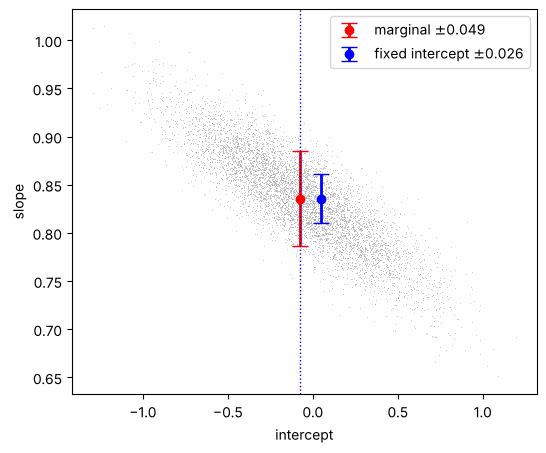

In [6]:
# 1e: your work here
d = load('p1e_slope_intercept_samples')
a, b = d['slope'].to_numpy(), d['intercept'].to_numpy()
rho = np.corrcoef(a, b)[0, 1]
sig_marg = a.std(ddof=1)
# slope at fixed intercept: remove the part of the slope that follows the intercept
# (the residual scatter of slope about its linear regression on intercept)
slope_on_b = np.cov(a, b)[0, 1] / b.var(ddof=1)
sig_cond = np.std(a - slope_on_b*(b - b.mean()), ddof=2)
# same thing directly: the samples whose intercept is within a thin slice of its best value
b0 = np.median(b); sl = np.abs(b - b0) < 0.1*b.std()
print(f"rho = {rho:.3f}")
print(f"marginal sigma_slope = {sig_marg:.4f};  conditional (fixed intercept) = {sig_cond:.4f}  "
      f"[thin slice of {sl.sum()} samples: {a[sl].std(ddof=1):.4f}]")
print(f"ratio cond/marg = {sig_cond/sig_marg:.3f};  sqrt(1 - rho^2) = {np.sqrt(1 - rho**2):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(b, a, ',', color='0.6', alpha=0.5)
a_med = np.median(a)
ax.errorbar(b0, a_med, yerr=sig_marg, fmt='o', color='r', capsize=6, lw=2, label=rf'marginal $\pm${sig_marg:.3f}')
ax.errorbar(b0 + 0.05*np.ptp(b), a_med, yerr=sig_cond, fmt='o', color='b', capsize=6, lw=2,
            label=rf'fixed intercept $\pm${sig_cond:.3f}')
ax.axvline(b0, color='b', ls=':', lw=1)
ax.set_xlabel('intercept'); ax.set_ylabel('slope'); ax.legend(); plt.show()

**ANSWER:**

1. The marginal error on the slope (intercept marginalized over, just the spread of the slope column) is 0.049. The classmate's error, the spread of the slope at fixed intercept, is 0.026; I got it from the scatter of the slope about its linear regression on the intercept, and checked it with the samples in a thin slice around the median intercept (0.0255, same thing).

2. The ratio is 0.53, and the correlation coefficient is $\rho = -0.85$. For a 2-D Gaussian the conditional width is $\sigma_{\rm marg}\sqrt{1-\rho^2}$, and $\sqrt{1 - 0.851^2} = 0.53$, matching. So the stronger the correlation, the more fixing the intercept shrinks the slope error (it goes to zero as $|\rho| \to 1$). Fixing the intercept is the same as taking $1/\sqrt{I_{ii}}$ instead of inverting the whole Fisher matrix first. The plot shows both error bars on the samples: the red (marginal) one spans the whole cloud in slope, the blue (fixed intercept) one only the thin vertical slice through it.

3. The classmate's number is only right if the intercept is actually known exactly from somewhere else; otherwise (and here it isn't) quote the marginal 0.049.


## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

250 SNe, z = 0.023 - 0.149; sigma_mu,pec = 0.012 - 0.078 mag
quick least squares: M = -19.29, alpha = 0.149, beta = 2.80, gamma = -0.015; robust scatter 0.113 mag
largest positive (faint) residuals after standardization:
         2003cq  z = 0.0338  resid = +1.34 mag = +11.9 robust sigma
         2003kc  z = 0.0348  resid = +1.31 mag = +11.6 robust sigma
         390259  z = 0.1223  resid = +1.06 mag = +9.4 robust sigma
          21062  z = 0.1374  resid = +0.40 mag = +3.5 robust sigma
     PTSS-16efw  z = 0.0357  resid = +0.38 mag = +3.3 robust sigma
        PS15cze  z = 0.0403  resid = +0.34 mag = +3.0 robust sigma
         2010gn  z = 0.0315  resid = +0.32 mag = +2.9 robust sigma
         2007hx  z = 0.0788  resid = +0.32 mag = +2.8 robust sigma
most negative residual: -0.72 mag
flagged as contaminants: ['2003cq', '2003kc', '390259']
Spearman: HR vs x1 rho = -0.49, HR vs c rho = +0.74, HR vs host mass rho = +0.24, x1 vs host mass rho = -0.34
mean x1: massive hosts -0.37, low-mass ho

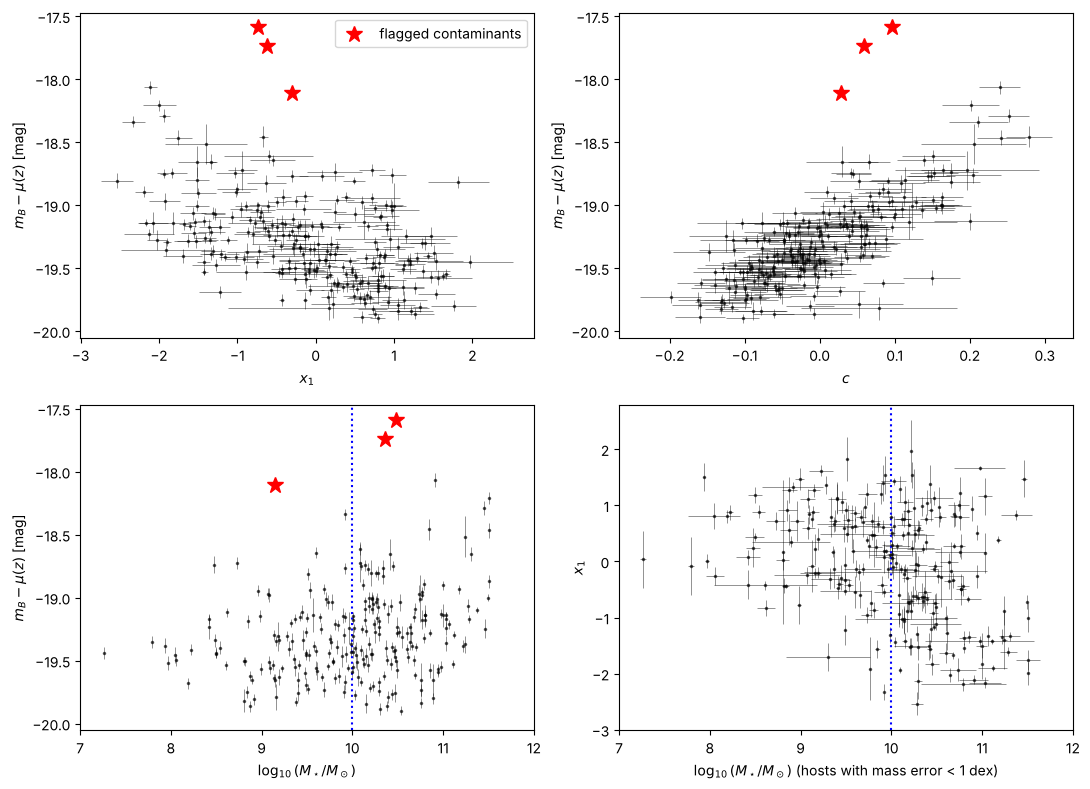

In [7]:
# 2a: your work here
from astropy.cosmology import FlatLambdaCDM
sn = load('p2_pantheon_sne')
z = sn['z'].to_numpy()
mu = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z).value
mB, x1, col = sn['mB'].to_numpy(), sn['x1'].to_numpy(), sn['c'].to_numpy()
smB, sx1, sc = sn['mB_err'].to_numpy(), sn['x1_err'].to_numpy(), sn['c_err'].to_numpy()
cmx, cmc, cxc = sn['cov_mB_x1'].to_numpy(), sn['cov_mB_c'].to_numpy(), sn['cov_x1_c'].to_numpy()
lm, slm = sn['host_logmass'].to_numpy(), sn['host_logmass_err'].to_numpy()
spec = 5/np.log(10) * 250 / (299792.458 * z)          # peculiar-velocity error in mu [mag]
hr = mB - mu                                            # Hubble residual (still contains M)
print(f"{len(z)} SNe, z = {z.min():.3f} - {z.max():.3f}; sigma_mu,pec = {spec.min():.3f} - {spec.max():.3f} mag")

# a quick unweighted linear fit of the Tripp relation, only to look at the data and find the obvious outliers
Th = (lm > 10).astype(float)
A = np.vstack([np.ones_like(z), -x1, col, Th]).T
p_ls = np.linalg.lstsq(A, hr, rcond=None)[0]
res = hr - A @ p_ls
mad = 1.4826 * np.median(np.abs(res - np.median(res)))
order = np.argsort(-res)
print(f"quick least squares: M = {p_ls[0]:.2f}, alpha = {p_ls[1]:.3f}, beta = {p_ls[2]:.2f}, gamma = {p_ls[3]:+.3f}; robust scatter {mad:.3f} mag")
print("largest positive (faint) residuals after standardization:")
for i in order[:8]:
    print(f"   {sn['name'][i]:>12s}  z = {z[i]:.4f}  resid = {res[i]:+.2f} mag = {res[i]/mad:+.1f} robust sigma")
print(f"most negative residual: {res.min():+.2f} mag")
bad = res > 0.8                                         # anything in the gap between 0.4 and 1.06 mag gives the same set
print("flagged as contaminants:", list(sn['name'][bad]))

# raw correlations
print(f"Spearman: HR vs x1 rho = {stats.spearmanr(hr, x1)[0]:+.2f}, HR vs c rho = {stats.spearmanr(hr, col)[0]:+.2f}, "
      f"HR vs host mass rho = {stats.spearmanr(hr[~bad], lm[~bad])[0]:+.2f}, x1 vs host mass rho = {stats.spearmanr(x1, lm)[0]:+.2f}")
hi_m = lm > 10
print(f"mean x1: massive hosts {x1[hi_m].mean():+.2f}, low-mass hosts {x1[~hi_m].mean():+.2f}")
print(f"raw mean HR (no Tripp correction, contaminants out): massive {np.mean(hr[hi_m & ~bad]):.3f}, low-mass {np.mean(hr[~hi_m & ~bad]):.3f} "
      f"-> raw difference {np.mean(hr[hi_m & ~bad]) - np.mean(hr[~hi_m & ~bad]):+.3f} mag")

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for a_, xv, xe, lab in [(ax[0,0], x1, sx1, '$x_1$'), (ax[0,1], col, sc, '$c$'), (ax[1,0], lm, None, r'$\log_{10}(M_\star/M_\odot)$')]:
    a_.errorbar(xv[~bad], hr[~bad], yerr=smB[~bad], xerr=xe[~bad] if xe is not None else None, fmt='k.', ms=3, elinewidth=0.5, alpha=0.6)
    a_.plot(xv[bad], hr[bad], 'r*', ms=12, label='flagged contaminants')
    a_.set_xlabel(lab); a_.set_ylabel(r'$m_B - \mu(z)$ [mag]')
ax[1,0].set_xlim(7, 12); ax[1,0].axvline(10, color='b', ls=':')
ax[0,0].legend()
ax[1,1].errorbar(lm[slm < 1], x1[slm < 1], xerr=slm[slm < 1], yerr=sx1[slm < 1], fmt='k.', ms=3, elinewidth=0.5, alpha=0.6)
ax[1,1].axvline(10, color='b', ls=':'); ax[1,1].set_xlim(7, 12)
ax[1,1].set_xlabel(r'$\log_{10}(M_\star/M_\odot)$ (hosts with mass error < 1 dex)'); ax[1,1].set_ylabel('$x_1$')
plt.tight_layout(); plt.show()

**ANSWER:**

1. Plots above: Hubble residuals $m_B - \mu(z)$ against $x_1$, $c$ and host mass (contaminant candidates as red stars), and $x_1$ against host mass.

2. The residuals go **down** with $x_1$ (Spearman $\rho = -0.49$): broader light curves are brighter (more negative magnitude). They go **up** with $c$ ($\rho = +0.74$): redder supernovae are fainter. Both are the signs the Tripp relation expects with $\alpha > 0$ and $\beta > 0$, because it has $-\alpha x_1$ and $+\beta c$. A quick linear fit gives $\alpha \approx 0.15$ and $\beta \approx 2.8$. The colour trend is the strongest thing in the data.

3. The raw residuals are actually *fainter* in massive hosts: the mean $m_B - \mu$ is $0.14$ mag larger for $\log M_\star > 10$ ($\rho = +0.24$ with host mass), which is the opposite sign to the published $\gamma < 0$. That's because host mass isn't independent of the other corrections. Massive hosts have lower-stretch supernovae (mean $x_1 = -0.37$ vs $+0.24$ in low-mass hosts, bottom-right plot, $\rho = -0.34$), and low-stretch supernovae are intrinsically fainter. That alone is worth $\alpha\,\Delta x_1 \approx 0.14 \times 0.61 \approx 0.09$ mag. So the raw trend mostly reflects the stretch–mass correlation, and $\gamma$ only means anything after $x_1$ and $c$ are corrected at the same time.

4. Yes. Three objects sit far above everything else: 2003cq (+1.34 mag), 2003kc (+1.31 mag) and 390259 (+1.06 mag) above the quick fit. That's 9–12 robust $\sigma$ (MAD-based scatter 0.11 mag). The next largest residual is only +0.40 mag (3.5 robust $\sigma$), so there's a clean gap. These three are my contaminants: fainter by more than a magnitude, as described, and three is within the 2–4 planted. The most negative residual (−0.72 mag) is brighter, not fainter, so it isn't one of the planted ones; I keep it as a real outlier.

5. $x_1$ and $c$ are dimensionless SALT2 parameters, and every term in the Tripp relation is a magnitude. So $\alpha$ is in magnitudes per unit of stretch and $\beta$ in magnitudes per unit of colour, i.e. both in mag. $\gamma$ is in mag too, since $\Theta$ is dimensionless.


### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

In [8]:
# 2b: your work here
# probability that each host is above 10^10 Msun, given its mass error (a few masses have errors of 3-10 dex,
# i.e. they are basically unknown; a hard step would put them on one side at random)
Phi = stats.norm.cdf((lm - 10) / slm)
print(f"hosts with mass error > 1 dex: {np.sum(slm > 1)}; their P(massive) = {np.round(Phi[slm > 1], 2)}")

names = ['M', 'alpha', 'beta', 'gamma', 'ln_sig_int']
# uniform priors (bounds); see the answer for the reasoning
lo_b = np.array([-21.0, -1.0, 0.0, -0.3, np.log(0.01)])
hi_b = np.array([-17.0,  1.0, 8.0,  0.3, np.log(1.0)])

def variance(a, b, ls, s):
    """sigma_i^2 = v^T C_i v + sigma_pec^2 + sigma_int^2 with v = (1, alpha, -beta)"""
    return (smB[s]**2 + a**2*sx1[s]**2 + b**2*sc[s]**2
            + 2*a*cmx[s] - 2*b*cmc[s] - 2*a*b*cxc[s]
            + spec[s]**2 + np.exp(2*ls))

def m2lnL(p, s=None, step=True):
    """-2 ln L for the Tripp relation; s selects the SNe used. step=False is model M0 (gamma = 0)."""
    if s is None: s = ~bad
    if step: M, a, b, gm, ls = p
    else:    (M, a, b, ls), gm = p, 0.0
    v = variance(a, b, ls, s)
    r = mB[s] - mu[s] - M + a*x1[s] - b*col[s] - gm*Phi[s]
    return np.sum(r**2 / v + np.log(2*np.pi*v))

def ln_post(p):
    if np.any(p < lo_b) or np.any(p > hi_b): return -np.inf
    return -0.5 * m2lnL(p)

# check the variance algebra against the explicit 3x3 matrix product for one SN
i, a_, b_ = 0, 0.15, 3.0
Ci = np.array([[smB[i]**2, cmx[i], cmc[i]], [cmx[i], sx1[i]**2, cxc[i]], [cmc[i], cxc[i], sc[i]**2]])
vv = np.array([1, a_, -b_])
print(f"v^T C v for SN 0: matrix {vv @ Ci @ vv:.6f}, term-by-term {variance(a_, b_, -np.inf, np.array([True] + [False]*(len(z)-1)))[0] - spec[0]**2:.6f}")
# how much do the off-diagonal terms matter? (median over SNe, at alpha=0.15, beta=3)
diag = smB**2 + a_**2*sx1**2 + b_**2*sc**2
offd = 2*a_*cmx - 2*b_*cmc - 2*a_*b_*cxc
print(f"median off-diagonal / diagonal part of v^T C v: {np.median(offd/diag):+.2f}  (range {np.min(offd/diag):+.2f} to {np.max(offd/diag):+.2f})")

# contaminants: check the cut with a mixture model on ALL 250 SNe (outliers = a broad component shifted faint)
def m2lnL_mix(q):
    M, a, b, gm, ls, lf, dm, lsw = q
    f = 1/(1 + np.exp(-lf))
    s = np.ones_like(z, bool)
    v = variance(a, b, ls, s)
    r = mB - mu - M + a*x1 - b*col - gm*Phi
    L_in = (1-f) * stats.norm.pdf(r, 0, np.sqrt(v))
    L_out = f * stats.norm.pdf(r, dm, np.sqrt(v + np.exp(2*lsw)))
    return -2*np.sum(np.log(L_in + L_out + 1e-300)), L_out/(L_in + L_out)
NM = dict(xatol=1e-9, fatol=1e-9, maxiter=40000)
mix = minimize(lambda q: m2lnL_mix(q)[0], [-19.3, 0.15, 3.0, -0.03, np.log(0.1), -4, 1.0, np.log(0.3)],
               method='Nelder-Mead', options=NM)
pout = m2lnL_mix(mix.x)[1]
print(f"mixture on all 250: alpha = {mix.x[1]:.3f}, beta = {mix.x[2]:.2f}, gamma = {mix.x[3]:+.3f}, sig_int = {np.exp(mix.x[4]):.3f}, "
      f"outlier fraction = {1/(1+np.exp(-mix.x[5])):.3f}, offset = {mix.x[6]:.2f} mag")
for i in np.argsort(-pout)[:6]:
    print(f"   P(outlier) {sn['name'][i]:>12s} = {pout[i]:.3f}")

hosts with mass error > 1 dex: 11; their P(massive) = [0.51 0.63 0.58 0.61 0.6  0.59 0.56 0.43 0.56 0.5  0.26]
v^T C v for SN 0: matrix 0.014399, term-by-term 0.014399
median off-diagonal / diagonal part of v^T C v: -0.56  (range -0.90 to +0.01)
mixture on all 250: alpha = 0.144, beta = 2.82, gamma = -0.028, sig_int = 0.105, outlier fraction = 0.012, offset = 1.24 mag
   P(outlier)       2003kc = 1.000
   P(outlier)       2003cq = 1.000
   P(outlier)       390259 = 1.000
   P(outlier)       2010gn = 0.000
   P(outlier)       PS16em = 0.000
   P(outlier)      PS15cze = 0.000


**ANSWER:**

1. With $\mathbf v = (1, \alpha, -\beta)$ and $C_i$ the covariance of $(m_B, x_1, c)$:
$$\mathbf v^T C_i \mathbf v = \sigma_{m_B}^2 + \alpha^2\sigma_{x_1}^2 + \beta^2\sigma_c^2 + 2\alpha\,{\rm Cov}(m_B,x_1) - 2\beta\,{\rm Cov}(m_B,c) - 2\alpha\beta\,{\rm Cov}(x_1,c).$$
The off-diagonal terms are there because $m_B$, $x_1$ and $c$ come out of the same light-curve fit, so their errors are correlated, and the variance of a linear combination has to include the covariances. They matter: for my SNe the off-diagonal part is typically −56% of the diagonal part (median), mainly from the positive Cov($m_B$, $c$) entering with $-2\beta$. I checked my term-by-term formula against the explicit matrix product for one SN (0.014399 both ways).

2. With $\Theta_i \to P_i$ (below), $r_i = m_{B,i} - M - \mu(z_i) + \alpha x_{1,i} - \beta c_i - \gamma P_i$ and $\sigma_i^2 = \mathbf v^T C_i \mathbf v + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2$:
$$-2\ln L = \sum_i \left[\frac{r_i^2}{\sigma_i^2} + \ln\left(2\pi\sigma_i^2\right)\right].$$
The $\ln\sigma_i^2$ term has to stay: $\sigma_i$ depends on $\alpha$, $\beta$ and $\sigma_{\rm int}$. Without it the fit can lower $\chi^2$ just by inflating $\sigma_{\rm int}$ (or $\alpha$, $\beta$ through the error terms). **Host masses:** 11 hosts have mass errors above 1 dex (up to 10 dex, i.e. the mass is basically unknown). A hard $\Theta$ would put each of those on one side of $10^{10}\,M_\odot$ essentially at random, so I replace $\Theta_i$ by $P_i = \Phi\big((\log M_{\star,i} - 10)/\sigma_{\log M,i}\big)$, the probability that the host is massive. For the well-measured hosts this is just 0 or 1 again; for the unknown ones it's ≈ 0.5. My test in 2e draws the hosts as 0/1 and checks this doesn't bias $\gamma$.

3. Priors, all uniform (so the MAP is the max-likelihood point):
   - $M \in [-21, -17]$ mag: SNe Ia peak near $-19.3$ for $H_0 = 70$; ±2 mag is very generous.
   - $\alpha \in [-1, 1]$ mag: literature values are ≈ 0.15. I don't force the sign, so the data have to give it.
   - $\beta \in [0, 8]$ mag: redder must be fainter (both dust, $R_B \approx 4$, and the intrinsic colour law give $\beta > 0$); 8 is well above anything published (≈ 3).
   - $\gamma \in [-0.3, 0.3]$ mag: symmetric so the sign isn't imposed, and 5× the published size, so any physically reasonable step fits inside. This is the one prior that matters, for the Bayes factor in 2d.
   - $\ln\sigma_{\rm int} \in [\ln 0.01, \ln 1]$: scale-invariant (flat in log), from 0.01 mag (better than any standard candle) to 1 mag (no standardization at all).

4. I sample $\ln\sigma_{\rm int}$. It keeps $\sigma_{\rm int}$ positive with no wall at zero for the walkers to pile up against, and the flat-in-log prior is the natural choice for a scale whose order of magnitude I don't want to assume. It doesn't affect the answer much here: the posterior is $\sigma_{\rm int} = 0.106 \pm 0.008$ mag, more than 10$\sigma$ from zero, so the $1/\sigma$ difference between the two priors changes by only about ±8% across the posterior.

5. I **remove** the three contaminants (2003cq, 2003kc, 390259). I found them from the residuals of a quick fit in 2a: +1.06 to +1.34 mag, with nothing between +0.40 and +1.06 mag, so any threshold from 0.45 to 1.0 mag gives the same three objects. Here the threshold choice really doesn't matter, which isn't usually true of a cut. As a check that doesn't need a cut, I also fit a mixture model to all 250 SNe: an inlier Tripp component (with $\sigma_{\rm int}$, so it can't label real scatter as outliers) plus an outlier component shifted faint, with free offset, width and fraction. It gives $P({\rm outlier}) = 1.000$ for exactly those three and $< 0.001$ for every other SN. It finds an offset of 1.24 mag, an outlier fraction of 1.2% (3/250), and the same $\alpha = 0.144$, $\beta = 2.82$, $\gamma = -0.028$, $\sigma_{\rm int} = 0.105$ as the cut sample. **What the cut costs:** 3 of 250 SNe (1.2%), so almost no precision. The real risks of a cut are (a) a threshold that also catches genuine tail SNe, which would bias $\sigma_{\rm int}$ low and the error bars too small, and (b) not carrying the uncertainty about which objects are bad. Neither applies here, because the separation is so clean and the mixture agrees. The real outliers, e.g. the −0.72 mag one and the +0.3–0.4 mag ones, stay in, and $\sigma_{\rm int}$ absorbs them.


### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

start -> -2lnL = -266.1967, p = [-19.2943   0.1437   2.8164  -0.0301  -2.2521]
start -> -2lnL = -266.1967, p = [-19.2943   0.1437   2.8164  -0.0301  -2.2521]
start -> -2lnL = -266.1967, p = [-19.2943   0.1437   2.8164  -0.0301  -2.2521]
MAP +/- curvature: M = -19.2943 +/- 0.0134, alpha = 0.1437 +/- 0.0092, beta = 2.8164 +/- 0.1001, gamma = -0.0301 +/- 0.0197, ln_sig_int = -2.2521 +/- 0.0783


chain 0: start centre gamma = +0.167, sig_int = 0.230; acceptance 0.55; tau = [54. 47. 51. 57. 56.]


chain 1: start centre gamma = -0.228, sig_int = 0.048; acceptance 0.55; tau = [47. 54. 45. 47. 41.]


chain 2: start centre gamma = +0.167, sig_int = 0.230; acceptance 0.55; tau = [53. 50. 51. 44. 54.]


chain 3: start centre gamma = +0.167, sig_int = 0.048; acceptance 0.55; tau = [53. 58. 49. 48. 41.]


chain length 5000 steps = 87 tau_max; burn-in 1000 = 17 tau_max


                mean      sd eti68_lb eti68_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
M           -19.2942  0.0137      -19      -19     8279    17191  1.00   0.00015  6.3e-05
alpha         0.1438  0.0093     0.13     0.15     8245    16757  1.00    0.0001  4.4e-05
beta           2.817  0.1016      2.7      2.9     8422    17492  1.00    0.0011  0.00048
gamma        -0.0303  0.0201    -0.05    -0.01     8362    17011  1.00   0.00022  9.4e-05
ln_sig_int    -2.241  0.0794     -2.3     -2.2     9049    16229  1.00   0.00083  0.00038
rough check, N/tau per chain summed: 8889


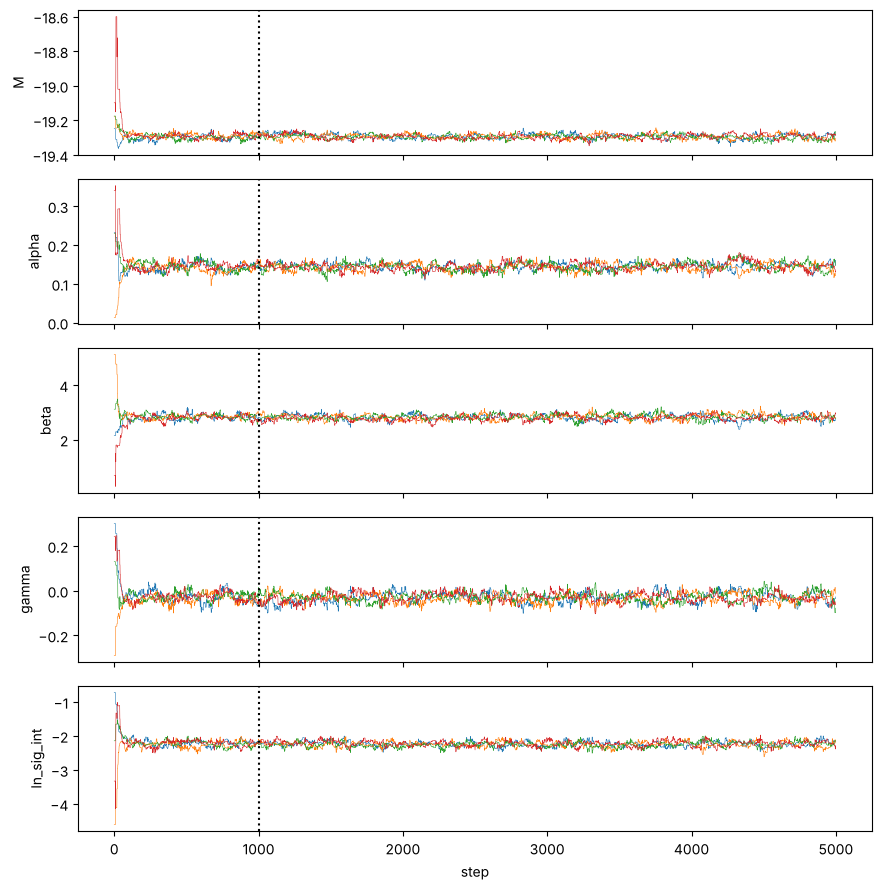

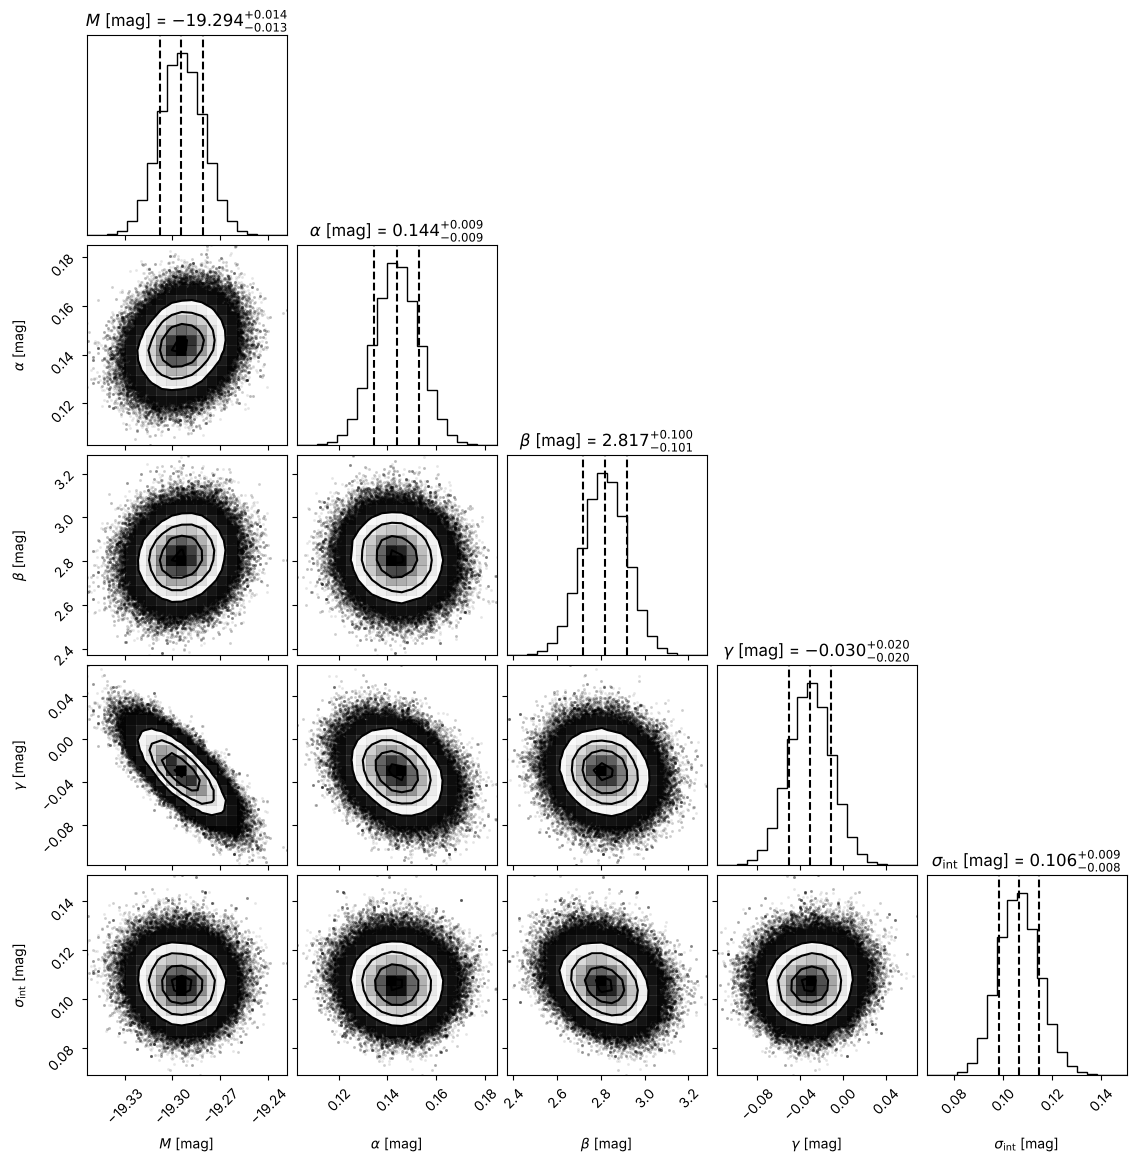

        M = -19.2943 +0.0137 -0.0134 mag
    alpha = 0.1438 +0.0093 -0.0092 mag
     beta = 2.8173 +0.1004 -0.1008 mag
    gamma = -0.0303 +0.0198 -0.0199 mag
sigma_int = 0.1065 +0.0085 -0.0082 mag
P(gamma < 0) = 0.935
correlation matrix (M, alpha, beta, gamma, sigma_int):
 [[ 1.    0.19  0.12 -0.77 -0.06]
 [ 0.19  1.   -0.07 -0.31 -0.06]
 [ 0.12 -0.07  1.   -0.13 -0.26]
 [-0.77 -0.31 -0.13  1.    0.07]
 [-0.06 -0.06 -0.26  0.07  1.  ]]
sigma_gamma with M fixed at MAP: 0.0126;  marginal (posterior std): 0.0201;  ratio 0.63; sqrt(1 - rho_(M,gamma)^2) = 0.64


In [9]:
# 2c: your work here
import emcee, corner
import arviz as az

def hessian(f, p, h=1e-4):
    n = len(p); H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            ei, ej = np.zeros(n), np.zeros(n); ei[i] = h; ej[j] = h
            H[i, j] = (f(p+ei+ej) - f(p+ei-ej) - f(p-ei+ej) + f(p-ei-ej)) / (4*h**2)
    return H

# (1) MAP: flat priors, so the MAP is the max-likelihood point inside the bounds. Several starts to be safe.
starts = [[-19.3, 0.15, 3.0, -0.05, np.log(0.1)], [-19.0, 0.0, 1.0, 0.1, np.log(0.3)], [-19.6, 0.4, 5.0, -0.2, np.log(0.03)]]
fits = [minimize(m2lnL, s0, method='Nelder-Mead', options=NM) for s0 in starts]
for f_ in fits: print(f"start -> -2lnL = {f_.fun:.4f}, p = {np.round(f_.x, 4)}")
map1 = min(fits, key=lambda f_: f_.fun)
p_map, m2_map1 = map1.x, map1.fun
C1 = 2*np.linalg.inv(hessian(m2lnL, p_map))        # factor 2: -2lnL
s_map = np.sqrt(np.diag(C1))
print("MAP +/- curvature:", ", ".join(f"{n} = {v:.4f} +/- {e:.4f}" for n, v, e in zip(names, p_map, s_map)))

# four independent emcee ensembles = four chains, each started from a different, overdispersed place:
# each ensemble's walkers are drawn from a box 10 curvature-sigmas wide around a random point that is itself
# 10 sigma away from the MAP, so the four chains start far from each other and from the posterior
nw, nsteps, burn = 32, 5000, 1000
np.random.seed(457)                                  # emcee uses numpy's global RNG
samplers, starts_used = [], []
for k in range(4):
    centre = p_map + 10*s_map*rng.choice([-1, 1], 5)
    p0 = np.clip(centre + 10*s_map*rng.standard_normal((nw, 5)), lo_b + 1e-6, hi_b - 1e-6)
    starts_used.append(centre)
    smp = emcee.EnsembleSampler(nw, 5, ln_post); smp.run_mcmc(p0, nsteps, progress=False)
    samplers.append(smp)
    print(f"chain {k}: start centre gamma = {centre[3]:+.3f}, sig_int = {np.exp(centre[4]):.3f}; "
          f"acceptance {smp.acceptance_fraction.mean():.2f}; tau = {np.round(smp.get_autocorr_time(quiet=True), 0)}")
tau_max = max(s_.get_autocorr_time(quiet=True).max() for s_ in samplers)
print(f"chain length {nsteps} steps = {nsteps/tau_max:.0f} tau_max; burn-in {burn} = {burn/tau_max:.0f} tau_max")

# (2) R-hat and ESS. Each ensemble is one chain; its walkers are laid end to end (walker by walker), so
# the draws keep their time order and ArviZ sees the real autocorrelation. (Interleaving the walkers
# step by step makes neighbouring draws look independent and inflates the ESS by ~tau.)
post = np.array([s_.get_chain(discard=burn).transpose(1, 0, 2).reshape(-1, 5) for s_ in samplers])  # (chain, draw, param)
idata = az.from_dict({'posterior': {n: post[:, :, i] for i, n in enumerate(names)}})
summ = az.summary(idata, ci_prob=0.68)
print(summ)
print("rough check, N/tau per chain summed:", int(4 * nw * (nsteps - burn) / tau_max))

# trace plot (one walker per chain shown) to look at the burn-in too
fig, ax = plt.subplots(5, 1, figsize=(9, 9), sharex=True)
for k, s_ in enumerate(samplers):
    chn = s_.get_chain()
    for i in range(5): ax[i].plot(chn[:, 0, i], lw=0.4, color=f'C{k}')
for i in range(5): ax[i].set_ylabel(names[i]); ax[i].axvline(burn, color='k', ls=':')
ax[-1].set_xlabel('step'); plt.tight_layout(); plt.show()

# (3) corner plot and the numbers
flat = post.reshape(-1, 5).copy()
flat[:, 4] = np.exp(flat[:, 4])                      # report sigma_int itself
labs = [r'$M$ [mag]', r'$\alpha$ [mag]', r'$\beta$ [mag]', r'$\gamma$ [mag]', r'$\sigma_{\rm int}$ [mag]']
corner.corner(flat, labels=labs, quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3f')
plt.show()
def summ_q(x):
    l, m_, h = np.percentile(x, [16, 50, 84]); return m_, h - m_, m_ - l
for n, i in zip(['M', 'alpha', 'beta', 'gamma', 'sigma_int'], range(5)):
    m_, up, dn = summ_q(flat[:, i]); print(f"{n:>9s} = {m_:.4f} +{up:.4f} -{dn:.4f} mag")
print(f"P(gamma < 0) = {np.mean(flat[:, 3] < 0):.3f}")

# (4) correlations, then fix M at the MAP and refit gamma
R = np.corrcoef(flat.T)
print("correlation matrix (M, alpha, beta, gamma, sigma_int):\n", np.round(R, 2))
fixM = lambda q: m2lnL(np.r_[p_map[0], q])
fM = minimize(fixM, p_map[1:], method='Nelder-Mead', options=NM)
CfM = 2*np.linalg.inv(hessian(fixM, fM.x))
sg_fixM, sg_marg = np.sqrt(CfM[2, 2]), flat[:, 3].std()
print(f"sigma_gamma with M fixed at MAP: {sg_fixM:.4f};  marginal (posterior std): {sg_marg:.4f};  ratio {sg_fixM/sg_marg:.2f}; "
      f"sqrt(1 - rho_(M,gamma)^2) = {np.sqrt(1 - R[0, 3]**2):.2f}")

**ANSWER:**

1. The MAP from three very different optimizer starts converges to the same point ($-2\ln L = -266.197$): $M = -19.294$, $\alpha = 0.144$, $\beta = 2.82$, $\gamma = -0.030$, $\sigma_{\rm int} = 0.105$ mag. Then I ran **four independent `emcee` ensembles**, one per chain (Day 14: the walkers inside one ensemble aren't independent chains). Each has 32 walkers and 5000 steps. For each chain I picked a random corner 10 curvature-$\sigma$ away from the MAP in every parameter and scattered the walkers ±10$\sigma$ around it. So the starts are far wider than the posterior and different for each chain (e.g. starting $\gamma$ at +0.17 vs −0.23 mag, $\sigma_{\rm int}$ at 0.23 vs 0.05 mag). The trace plots show every chain reaching the same region within a few hundred steps. I discard the first 1000 steps (17 $\tau$); the chains are 5000 steps = 87 $\tau_{\max}$ ($\tau \approx 41$–58 steps, acceptance 0.55).

2. From `az.summary` (each ensemble as one chain, walkers laid end to end so the draws keep their order): $\hat R = 1.00$ for all five parameters, `ess_bulk` 8200–9000 and `ess_tail` 16000–17500 (cross-check: $N/\tau \approx 8900$). I would have run longer if any $\hat R \ge 1.01$ (ArviZ's threshold), if `ess_bulk` or `ess_tail` were below about 400 for any parameter (my choice, about 100 per chain), or if the chains were shorter than 50 $\tau$. (A note on ArviZ: when I first passed the walkers interleaved step by step, it reported ESS ≈ 250,000. That's nonsense: it treats correlated walkers as independent draws. Ordering the draws by walker fixed it.)

3. Corner plot above. Medians with 16th–84th percentiles:
   - $\alpha = 0.1438 \pm 0.0093$ mag
   - $\beta = 2.82 \pm 0.10$ mag
   - $\gamma = -0.030 \pm 0.020$ mag
   - $\sigma_{\rm int} = 0.1065^{+0.0085}_{-0.0082}$ mag
   - (and $M = -19.294 \pm 0.014$ mag)

   All are close to symmetric. $P(\gamma < 0) = 0.94$.

4. The only strong correlation is **$M$–$\gamma$, $\rho = -0.77$**. $M$ is the absolute magnitude of SNe in low-mass hosts and $M + \gamma$ that of SNe in massive hosts, and 57% of my SNe are in massive hosts. The data mostly pin down the overall mean brightness, a weighted average of the two groups, so making $M$ brighter can be compensated by making $\gamma$ fainter. Next is $\alpha$–$\gamma$ ($-0.31$), because $x_1$ is correlated with host mass (2a.3); $\beta$–$\sigma_{\rm int}$ is $-0.26$ (colour errors and intrinsic scatter both add variance). Fixing $M$ at its MAP and refitting gives $\sigma_\gamma = 0.0126$ mag, against the marginal 0.0201: a ratio of 0.63, matching $\sqrt{1 - \rho_{M\gamma}^2} = 0.64$, exactly as in 1e. Quoting the fixed-$M$ error would make the step look 1.6× more significant than it is.


### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [10]:
# 2d: your work here
# M0: gamma = 0, parameters (M, alpha, beta, ln_sig_int)
m2_0 = lambda q: m2lnL(q, step=False)
fits0 = [minimize(m2_0, np.delete(s0, 3), method='Nelder-Mead', options=NM) for s0 in starts]
map0 = min(fits0, key=lambda f_: f_.fun)
C0 = 2*np.linalg.inv(hessian(m2_0, map0.x))
N_sn = np.sum(~bad)

def ln_Z_laplace(m2min, C, widths):
    """ln P(D|M) ~ ln L_max + ln prior(theta_hat) + d/2 ln 2pi + 1/2 ln det C, with uniform priors"""
    d_ = len(widths)
    return -0.5*m2min - np.sum(np.log(widths)) + 0.5*d_*np.log(2*np.pi) + 0.5*np.linalg.slogdet(C)[1]

w_all = hi_b - lo_b
lnZ1 = ln_Z_laplace(m2_map1, C1, w_all)
lnZ0 = ln_Z_laplace(map0.fun, C0, np.delete(w_all, 3))
print(f"-2lnL_max: M0 {map0.fun:.2f}, M1 {m2_map1:.2f}; Delta(-2lnL) = {map0.fun - m2_map1:.2f} for 1 extra parameter")
print(f"gamma prior: uniform on [{lo_b[3]}, {hi_b[3]}] mag (width {w_all[3]:.1f} mag)")
print(f"2 ln B_10 (Laplace) = {2*(lnZ1 - lnZ0):+.2f}")
w2 = w_all.copy(); w2[3] *= 2
print(f"  with the gamma prior twice as wide: 2 ln B_10 = {2*(ln_Z_laplace(m2_map1, C1, w2) - lnZ0):+.2f}")
# Occam factor pieces for gamma alone
print(f"  pieces: likelihood gain {map0.fun - m2_map1:.2f};  Occam penalty -2 ln(sqrt(2pi) sigma_gamma / width) = "
      f"{-2*np.log(np.sqrt(2*np.pi)*np.sqrt(C1[3,3])/w_all[3]):.2f}")
# check Laplace against brute-force numerical integration over gamma at the profile (other params re-optimized)
gg = np.linspace(-0.3, 0.3, 121)
prof = np.array([minimize(lambda q: m2lnL(np.r_[q[:3], g_, q[3]]), np.delete(p_map, 3), method='Nelder-Mead', options=NM).fun for g_ in gg])
print(f"  1-D check (profile in gamma, integrated): Delta(2 ln Z) from gamma integral = "
      f"{2*np.log(np.trapezoid(np.exp(-0.5*(prof - prof.min())), gg) / w_all[3]) - (m2_map1 - prof.min()) + (map0.fun - m2_map1):+.2f}")

BIC1 = m2_map1 + 5*np.log(N_sn); BIC0 = map0.fun + 4*np.log(N_sn)
print(f"BIC0 - BIC1 = {BIC0 - BIC1:+.2f}  (N = {N_sn})")

g_med = np.median(flat[:, 3])
print(f"gamma = {g_med:+.3f} +/- {sg_marg:.3f} mag; published -0.06 is {abs(-0.06 - g_med)/sg_marg:.1f} sigma from mine; "
      f"a -0.06 step would be a {0.06/sg_marg:.1f} sigma detection with my sigma_gamma")
# expected 2lnB if the true step were -0.06 (Trotta: lambda^2 - 2 ln(width/(sqrt(2pi) sigma)))
lam = 0.06/sg_marg
print(f"if gamma were really -0.06, expected 2 ln B ~ {lam**2 - 2*np.log(w_all[3]/(np.sqrt(2*np.pi)*sg_marg)):+.1f}")

-2lnL_max: M0 -263.89, M1 -266.20; Delta(-2lnL) = 2.31 for 1 extra parameter
gamma prior: uniform on [-0.3, 0.3] mag (width 0.6 mag)
2 ln B_10 (Laplace) = -2.68
  with the gamma prior twice as wide: 2 ln B_10 = -4.07
  pieces: likelihood gain 2.31;  Occam penalty -2 ln(sqrt(2pi) sigma_gamma / width) = 4.99


  1-D check (profile in gamma, integrated): Delta(2 ln Z) from gamma integral = -2.68
BIC0 - BIC1 = -3.20  (N = 247)
gamma = -0.030 +/- 0.020 mag; published -0.06 is 1.5 sigma from mine; a -0.06 step would be a 3.0 sigma detection with my sigma_gamma
if gamma were really -0.06, expected 2 ln B ~ +4.0


**ANSWER:**

1. With uniform priors (same for $M$, $\alpha$, $\beta$, $\ln\sigma_{\rm int}$ in both models, so those cancel) and the Laplace approximation $\ln Z \approx \ln L_{\max} + \ln\pi(\hat\theta) + \frac d2\ln 2\pi + \frac12\ln\det C$:
   - $\Delta(-2\ln L_{\max}) = 2.31$ in favour of $M_1$ for one extra parameter;
   - with the $\gamma$ prior uniform on $[-0.3, 0.3]$ mag (defended in 2b: symmetric, 5× the published step), **$2\ln B_{1,0} = -2.7$**;
   - the Occam penalty for $\gamma$ is $-2\ln(\sqrt{2\pi}\,\sigma_\gamma/0.6) = 5.0$, larger than the likelihood gain of 2.3.

   I checked the Laplace number by integrating the profile likelihood in $\gamma$ numerically: the same −2.68. With the prior twice as wide ($\pm 0.6$ mag), $2\ln B_{1,0} = -4.1$, lower by $2\ln 2 = 1.39$ as expected. The fit doesn't change, only the prior volume. (A narrower $\pm 0.15$ mag prior would give −1.3.)

2. $\mathrm{BIC}_0 - \mathrm{BIC}_1 = -3.2$ (N = 247). This agrees in sign and roughly in size with the Laplace answer.

3. On the Day 8 scale, $|2\ln B| = 2.7$–4.1 and $|\Delta{\rm BIC}| = 3.2$ are **"positive" evidence for $M_0$ (no step)**. That's not much, and its size depends on the prior width, so my data don't need $\gamma$. My $\gamma = -0.030 \pm 0.020$ mag is 1.5$\sigma$ from zero and also 1.5$\sigma$ from the published −0.06 mag, so it's consistent with both. **Could I have detected a −0.06 mag step?** Only marginally. With $\sigma_\gamma = 0.020$ mag a −0.06 step would be a 3.0$\sigma$ measurement, and the Trotta estimate $2\ln B \approx \lambda^2 - 2\ln(w/\sqrt{2\pi}\sigma_\gamma)$ gives about +4 if it were real: "positive", not "strong". So 250 low-$z$ SNe could at best have given positive evidence for a step the published size. Not detecting one says little about whether it's real, and I'd need roughly 4× more SNe (σ_γ ≈ 0.010) to make a −0.06 step a ≥ 6$\sigma$, "very strong" detection. (2e also shows my $\hat\gamma$ is biased slightly toward zero, by about 0.4$\sigma$, which makes a real step a bit harder to see.)


### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

         M: coverage 0.68, mean pull -0.34, std pull 0.81, mean estimate -19.305 (truth -19.300)
     alpha: coverage 0.65, mean pull -0.58, std pull 0.91, mean estimate +0.144 (truth +0.150)
      beta: coverage 0.05, mean pull -2.35, std pull 0.92, mean estimate +2.763 (truth +3.000)
     gamma: coverage 0.75, mean pull +0.39, std pull 0.83, mean estimate -0.071 (truth -0.080)
ln_sig_int: coverage 0.62, mean pull +0.39, std pull 1.15, mean estimate -2.098 (truth -2.120)
pooled coverage over all 5 parameters: 0.55


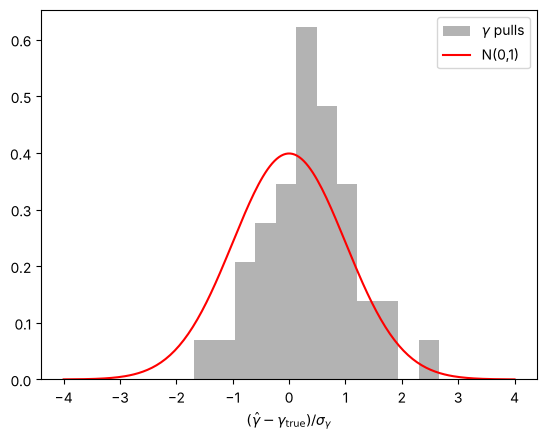

In [11]:
# 2e: your work here
# Coverage test. Truth I choose (not my fitted values): M = -19.30, alpha = 0.15, beta = 3.00, gamma = -0.08, sig_int = 0.12 mag.
# Each fake dataset uses my real redshifts, real per-SN covariance matrices, real host-mass probabilities;
# the true x1, c are my observed ones, and the "observed" (mB, x1, c) are drawn with the full 3x3 covariance.
# The host of each SN is drawn massive with probability Phi, so the soft step in my model is also being tested.
# FAILURE (decided before running): with 40 datasets, the 68% coverage of any parameter outside
# 0.68 +/- 2*sqrt(0.68*0.32/40) = [0.53, 0.83], or a mean pull |<z>| > 2/sqrt(40) = 0.32, or std(z) outside [0.75, 1.25].
truth = np.array([-19.30, 0.15, 3.00, -0.08, np.log(0.12)])
nsim = 40
keep = ~bad
Cfull = np.zeros((len(z), 3, 3))
Cfull[:, 0, 0], Cfull[:, 1, 1], Cfull[:, 2, 2] = smB**2, sx1**2, sc**2
Cfull[:, 0, 1] = Cfull[:, 1, 0] = cmx; Cfull[:, 0, 2] = Cfull[:, 2, 0] = cmc; Cfull[:, 1, 2] = Cfull[:, 2, 1] = cxc
Lchol = np.linalg.cholesky(Cfull)
real = (mB, x1, col)
est, err = np.zeros((nsim, 5)), np.zeros((nsim, 5))
for k in range(nsim):
    Mt, at, bt, gt, lst = truth
    massive = rng.random(len(z)) < Phi
    # true x1, c are the real observed ones (real[1], real[2]), not the previous loop's fakes
    m_true = Mt + mu - at*real[1] + bt*real[2] + gt*massive + rng.normal(0, np.exp(lst), len(z)) + rng.normal(0, spec)
    noise = np.einsum('nij,nj->ni', Lchol, rng.standard_normal((len(z), 3)))
    mB, x1, col = m_true + noise[:, 0], real[1] + noise[:, 1], real[2] + noise[:, 2]   # globals used by m2lnL
    f_ = minimize(m2lnL, truth, method='Nelder-Mead', options=NM)
    est[k] = f_.x; err[k] = np.sqrt(np.diag(2*np.linalg.inv(hessian(m2lnL, f_.x))))
mB, x1, col = real                                   # put the real data back
zs = (est - truth) / err
for i, n in enumerate(names):
    cov68 = np.mean(np.abs(zs[:, i]) < 1)
    print(f"{n:>10s}: coverage {cov68:.2f}, mean pull {zs[:, i].mean():+.2f}, std pull {zs[:, i].std(ddof=1):.2f}, "
          f"mean estimate {est[:, i].mean():+.3f} (truth {truth[i]:+.3f})")
print(f"pooled coverage over all 5 parameters: {np.mean(np.abs(zs) < 1):.2f}")

plt.hist(zs[:, 3], 12, density=True, color='0.7', label=r'$\gamma$ pulls')
xx = np.linspace(-4, 4, 200); plt.plot(xx, stats.norm.pdf(xx), 'r-', label='N(0,1)')
plt.xlabel(r'$(\hat\gamma - \gamma_{\rm true})/\sigma_\gamma$'); plt.legend(); plt.show()

**ANSWER:**

**Test:** fake data from a truth I chose, not my fitted values: $M = -19.30$, $\alpha = 0.15$, $\beta = 3.00$, $\gamma = -0.08$, $\sigma_{\rm int} = 0.12$ mag. The fakes use my real redshifts, real 3×3 covariances, real peculiar-velocity errors and real host-mass probabilities (each host drawn massive or not with probability $P_i$, so the soft step is tested too). The true $x_1, c$ are my observed values, and the "observed" $m_B, x_1, c$ are drawn from the full covariance. I fit 40 datasets by maximum likelihood with curvature errors (the same likelihood as the MCMC).

**Failure, decided before running:** for any parameter, 68% coverage outside $0.68 \pm 2\sqrt{0.68 \cdot 0.32/40} = [0.53, 0.83]$, or mean pull $|\langle z\rangle| > 2/\sqrt{40} = 0.32$, or std of the pulls outside [0.75, 1.25].

**First run, a bug:** the first version failed badly ($\sigma_{\rm int}$ coverage 0.03, pulls of +4.7). The loop overwrote the global `x1`, `c` arrays and then used them as the "truth" in the next dataset, so the noise piled up from one fake to the next. That's exactly the kind of mistake this test is for. After fixing it:

| parameter | coverage | mean pull | std pull | mean $\hat\theta$ (truth) |
|---|---|---|---|---|
| $M$ | 0.68 | −0.34 | 0.81 | −19.305 (−19.300) |
| $\alpha$ | 0.65 | −0.58 | 0.91 | 0.144 (0.150) |
| $\beta$ | **0.05** | **−2.35** | 0.92 | 2.763 (3.000) |
| $\gamma$ | 0.75 | +0.39 | 0.83 | −0.071 (−0.080) |
| $\sigma_{\rm int}$ | 0.62 | +0.39 | 1.15 | (in ln) |

**The pipeline fails for $\beta$, and marginally for $\alpha$, $M$, $\gamma$ and $\sigma_{\rm int}$ on the mean pull.** $\beta$ comes out 8% low (2.76 vs 3.00, −2.35 pulls on average). This is not a bug, it's the attenuation bias from Lab 04. The Tripp likelihood puts the colour and stretch *errors* into the variance, but it still uses the observed $c$ and $x_1$ as if they were the true ones. With $\sigma_c \approx 0.034$ against a colour spread of 0.09, regression dilution pulls $\beta$ toward zero; $\alpha$ is affected less because $\sigma_{x_1}/{\rm spread}(x_1)$ is smaller. The $\gamma$ bias is small, +0.009 mag (≈ 0.4$\sigma$ toward zero), and comes through $\gamma$'s correlation with $\alpha$, since $x_1$ and $c$ correlate with host mass.

**What it means for my real numbers:** my $\beta = 2.82 \pm 0.10$ is probably ~0.2 too low (the true value is probably ≈ 3.0, closer to published values), and $\gamma$ is probably slightly more negative than −0.030, by about 0.01 mag. Neither changes the 2d conclusion: a ~0.4$\sigma$ shift in $\gamma$ moves $2\ln B$ by about 1. **The fix:** model the true $x_1$ and $c$ as latent variables drawn from a population (a Gaussian in each, as in the Lab 04 / Day 10 generative model) and integrate them out, which gives a 3-D Gaussian likelihood for $(m_B, x_1, c)$. Alternatively, do what Pantheon+ does and calibrate the bias with simulations like these and subtract it. I didn't have time to implement the generative version; the test tells me where it would matter (β) and where it doesn't much (γ).


## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

In [12]:
# 3a: your work here

**REFEREE REPORT:**

*your report goes here*

### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**

*your answer goes here*

Get started. You know how to do all of this. If not, there's something in a lab or class notebook that can help. Slack me with questions. Best of luck.